In [193]:
print("Speech Emotion Recognition Project")
print("Let's detect emotions from speech!")

Speech Emotion Recognition Project
Let's detect emotions from speech!


In [194]:
!pip install librosa numpy pandas scikit-learn matplotlib soundfile

In [195]:
import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import soundfile as sf

print("All libraries imported successfully!")

All libraries imported successfully!


In [196]:
import os
import zipfile
import urllib.request
from pathlib import Path

# Dataset download link (16 kHz version)
url = "https://zenodo.org/records/11063852/files/Audio_Speech_Actors_01-24_16k.zip?download=1"

# Download dataset
print("Downloading RAVDESS dataset...")

urllib.request.urlretrieve(url, "ravdess.zip")

print("Download completed!")

# Extract dataset
os.makedirs("ravdess_data", exist_ok=True)

with zipfile.ZipFile("ravdess.zip", "r") as zip_ref:
    zip_ref.extractall("ravdess_data")

print("Dataset extracted successfully!")

Download completed!
Dataset extracted successfully!


In [197]:
dataset_path = Path("ravdess_data")

audio_files = list(dataset_path.rglob("*.wav"))

print("Total audio recordings:", len(audio_files))

print("\nFirst 5 audio files:")

for file in audio_files[:5]:
    print(file.name)

Total audio recordings: 1440

First 5 audio files:
03-01-08-01-02-02-15.wav
03-01-01-01-01-01-15.wav
03-01-03-01-02-02-15.wav
03-01-04-01-01-01-15.wav
03-01-08-01-01-01-15.wav


In [198]:
# Select the four emotions
emotion_map = {
    "01": "Neutral",
    "03": "Happy",
    "04": "Sad",
    "05": "Angry"
}

features = []
labels = []
actors = []

print("Extracting audio features...")

for file in audio_files:

    # Get emotion code from filename
    emotion_code = file.name.split("-")[2]

    # Skip unwanted emotions
    if emotion_code not in emotion_map:
        continue

    # Load audio
    audio, sample_rate = librosa.load(
        str(file), sr=16000
    )

    # Extract 40 MFCC coefficients
    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sample_rate,
        n_mfcc=40
    )

    # Convert variable-length audio into fixed-length features
    mfcc_mean = np.mean(mfcc, axis=1)
    mfcc_std = np.std(mfcc, axis=1)

    feature_vector = np.concatenate(
        [mfcc_mean, mfcc_std]
    )

    features.append(feature_vector)
    labels.append(emotion_map[emotion_code])

    # Store actor ID for proper train/test splitting later
    actors.append(file.name.split("-")[-1].replace(".wav", ""))

print("Feature extraction completed!")
print("Total samples:", len(features))
print("Features per sample:", len(features[0]))

Extracting audio features...
Feature extraction completed!
Total samples: 672
Features per sample: 80


In [199]:
X = np.array(features)
y = np.array(labels)
groups = np.array(actors)

print("Feature shape:", X.shape)
print("Label shape:", y.shape)

print("\nEmotion distribution:")
print(pd.Series(y).value_counts())

Feature shape: (672, 80)
Label shape: (672,)

Emotion distribution:
Happy      192
Sad        192
Angry      192
Neutral     96
Name: count, dtype: int64


In [200]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

# Split recordings by actor
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training actors:", len(np.unique(groups[train_idx])))
print("Testing actors:", len(np.unique(groups[test_idx])))

Training samples: 504
Testing samples: 168
Training actors: 18
Testing actors: 6


In [201]:
from sklearn.ensemble import RandomForestClassifier

# Create the model
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [202]:
from sklearn.metrics import accuracy_score

# Predict emotions
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 54.17 %


In [203]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       Angry       0.75      0.62      0.68        48
       Happy       0.47      0.46      0.46        48
     Neutral       0.67      0.25      0.36        24
         Sad       0.46      0.69      0.55        48

    accuracy                           0.54       168
   macro avg       0.59      0.51      0.51       168
weighted avg       0.57      0.54      0.54       168



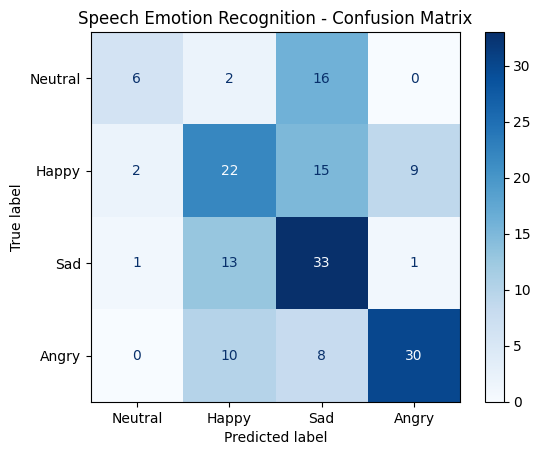

In [204]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Create confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Neutral", "Happy", "Sad", "Angry"]
)

# Display confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Neutral", "Happy", "Sad", "Angry"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Speech Emotion Recognition - Confusion Matrix")
plt.show()

In [205]:
def predict_emotion(audio_path):

    # Load uploaded audio
    audio, sr = librosa.load(audio_path, sr=16000)

    # Extract MFCC features
    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=40
    )

    # Calculate mean and standard deviation
    mfcc_mean = np.mean(mfcc, axis=1)
    mfcc_std = np.std(mfcc, axis=1)

    # Combine features
    feature_vector = np.concatenate(
        [mfcc_mean, mfcc_std]
    )

    # Predict emotion
    prediction = model.predict(
        feature_vector.reshape(1, -1)
    )

    probabilities = model.predict_proba(
        feature_vector.reshape(1, -1)
    )

    confidence = np.max(probabilities) * 100

    print("Predicted Emotion:", prediction[0])
    print("Model Confidence:", round(confidence, 2), "%")

    return prediction[0]

In [206]:
# Get actors used for testing
test_actors = set(groups[test_idx])

# Select one recording from a test actor
test_file = next(
    file for file in audio_files
    if file.name.split("-")[2] in emotion_map
    and file.name.split("-")[-1].replace(".wav", "") in test_actors
)

print("Testing audio:", test_file.name)

# Predict emotion
predict_emotion(str(test_file))

Testing audio: 03-01-01-01-01-02-17.wav
Predicted Emotion: Neutral
Model Confidence: 43.0 %


np.str_('Neutral')

In [207]:
import joblib

# Save the trained model
joblib.dump(model, "speech_emotion_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [208]:
import json

config = {
    "emotions": emotion_map,
    "sample_rate": 16000,
    "mfcc_features": 40,
    "total_features": 80,
    "model": "Random Forest"
}

with open("config.json", "w") as file:
    json.dump(config, file, indent=4)

print("Configuration saved successfully!")

Configuration saved successfully!


In [209]:
import os

print("Saved project files:")

for file in ["speech_emotion_model.pkl", "config.json"]:
    print(file, "-", os.path.getsize(file), "bytes")

Saved project files:
speech_emotion_model.pkl - 3617097 bytes
config.json - 225 bytes
